In [1]:
# # Colab Intro
# Wprowadzenie do środowiska Google Colab oraz podstawowych operacji obliczeniowych, graficznych i multimedialnych w języku Python.

In [2]:
# ## Obliczanie sumy ciągu geometrycznego
#
# **Ciąg geometryczny** to ciąg liczbowy (a_n), w którym każdy kolejny wyraz powstaje
# poprzez pomnożenie poprzedniego wyrazu przez stałą wartość q != 0, zwaną ilorazem ciągu:
# a_n = a_1 * q^(n-1)
#
# Wzór na sumę n pierwszych wyrazów:
# Dla ilorazu q != 1:
# S_n = a_1 * (1 - q^n) / (1 - q)
#
# Gdy q = 1, każdy wyraz jest równy a_1, a suma wynosi:
# S_n = n * a_1

def suma_ciagu_geom(a1: float, q: float, n: int) -> float:
    """Oblicza sumę n pierwszych wyrazów ciągu geometrycznego."""
    if q == 1:
        return a1 * n
    return a1 * (1 - q**n) / (1 - q)

# Przykład: a1 = 2, q = 3, n = 5
a1, q, n = 2, 3, 5
wynik = suma_ciagu_geom(a1, q, n)
print(f"Suma {n} wyrazów ciągu (a1={a1}, q={q}) wynosi: {wynik}")

Suma 5 wyrazów ciągu (a1=2, q=3) wynosi: 242.0


In [3]:
# 3. Komórka kodu licząca 2+2
2 + 2

4

In [4]:
# 4. Komórka kodu licząca pi^pi
import math

wynik_pi = math.pi ** math.pi
print(f"pi^pi = {wynik_pi}")

pi^pi = 36.4621596072079


In [5]:
# 5. Komórka kodu licząca sumę kwadratów liczb od 1 do 100
suma_kwadratow = sum(k**2 for k in range(1, 101))
print(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}")

Suma kwadratów liczb od 1 do 100 wynosi: 338350


In [6]:
# 6. Zapis wyniku sumy kwadratów do pliku colab_wynik.txt
import os

sciezka_pliku = "colab_wynik.txt"

with open(sciezka_pliku, "w", encoding="utf-8") as f:
  f.write(f"Suma kwadratów liczb od 1 do 100 wynosi: {suma_kwadratow}\n")

# Domyślny katalog roboczy w Colabie to /content/
print(f"Plik został zapisany pod ścieżką: {os.path.abspath(sciezka_pliku)}")

Plik został zapisany pod ścieżką: /content/colab_wynik.txt


<>:11: SyntaxWarning: invalid escape sequence '\i'
<>:11: SyntaxWarning: invalid escape sequence '\i'
/tmp/ipykernel_5008/2152050084.py:11: SyntaxWarning: invalid escape sequence '\i'
  plt.title("Wykres funkcji $y = k^2$ dla $k \in [1, 20]$")


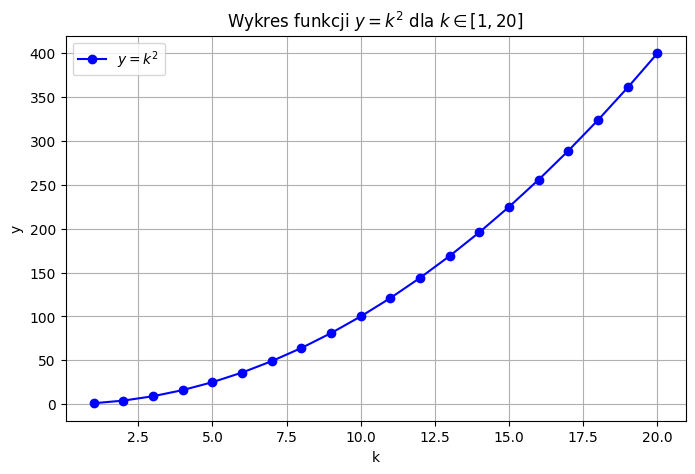

Wykres zapisano pod ścieżką: /content/wykres.png


In [7]:
# 7 & 8. Tworzenie wykresu y = k^2 dla k = 1,...,20 i zapis do wykres.png
import os
import matplotlib.pyplot as plt
import numpy as np

k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(8, 5))
plt.plot(k, y, "o-", color="blue", label="$y = k^2$")
plt.title("Wykres funkcji $y = k^2$ dla $k \in [1, 20]$")
plt.xlabel("k")
plt.ylabel("y")
plt.grid(True)
plt.legend()

# Zapis do pliku
sciezka_wykresu = "wykres.png"
plt.savefig(sciezka_wykresu, dpi=300)
plt.show()

print(f"Wykres zapisano pod ścieżką: {os.path.abspath(sciezka_wykresu)}")

In [11]:
# 9. Animacja wahadła, zapis do pliku video.mp4, konwersja do GIF oraz osadzenie w notebooku
import os
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import imageio
from IPython.display import Video

# Parametry wahadła
L = 1.0  # długość wahadła [m]
g = 9.81  # przyspieszenie ziemskie [m/s^2]
theta0 = np.radians(30)  # kąt początkowy (30 stopni)
omega = np.sqrt(g / L)  # częstość kołowa

fps = 30
duration = 4  # sekundy
t = np.linspace(0, duration, fps * duration)

# Kąt w czasie
theta = theta0 * np.cos(omega * t)

# Pozycje położenia ciężarka (x, y)
x = L * np.sin(theta)
y = -L * np.cos(theta)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1.2 * L, 1.2 * L)
ax.set_ylim(-1.2 * L, 0.2 * L)
ax.set_aspect("equal")
ax.grid(True)
ax.set_title("Animacja wahadła prostego")

(line,) = ax.plot([], [], "o-", lw=2, color="crimson", markersize=10)


def init():
  line.set_data([], [])
  return (line,)


def update(frame):
  line.set_data([0, x[frame]], [0, y[frame]])
  return (line,)


anim = animation.FuncAnimation(
    fig, update, frames=len(t), init_func=init, blit=True, interval=1000 / fps
)

# Zapis do pliku MP4 przy użyciu FFmpeg
video_path = "video.mp4"
anim.save(video_path, writer="ffmpeg", fps=fps)
plt.close()
print(f"Wideo zapisano w: {os.path.abspath(video_path)}")

# Konwersja MP4 na GIF w tej samej komórce
gif_path = "video.gif"
reader = imageio.get_reader(video_path)
writer = imageio.get_writer(gif_path, fps=fps)
for frame in reader:
  writer.append_data(frame)
writer.close()
print(f"Animowany plik GIF zapisano w: {os.path.abspath(gif_path)}")

# Osadzenie wideo w notebooku
Video(video_path, embed=True, width=400)

Wideo zapisano w: /content/video.mp4
Animowany plik GIF zapisano w: /content/video.gif


In [9]:
# 10. Konwersja video.mp4 na animowany plik video.gif
import os
import imageio

# Odczyt pliku video.mp4 i konwersja klatka po klatce do formatu GIF
reader = imageio.get_reader("video.mp4")
fps = reader.get_meta_data().get("fps", 30)

gif_path = "video.gif"
writer = imageio.get_writer(gif_path, fps=fps)

for frame in reader:
  writer.append_data(frame)
writer.close()

print(f"Animowany plik GIF zapisano pod ścieżką: {os.path.abspath(gif_path)}")
# Domyślnie plik w Colabie znajduje się w ścieżce katalogu roboczego: /content/video.gif

Animowany plik GIF zapisano pod ścieżką: /content/video.gif


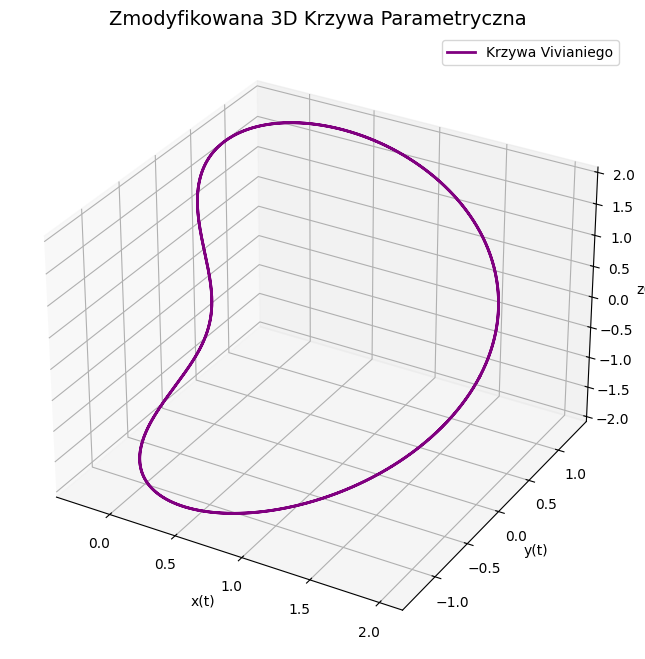

Wykres krzywej został zapisany w ścieżce: /content/parametric_curve.png


In [10]:
# 11. Modyfikacja krzywej parametrycznej 3D (Krzywa Vivianiego) oraz zapis do parametric_curve.png
import os
import matplotlib.pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D

# Zmodyfikowane równania parametryczne (np. Krzywa Vivianiego / Helisa sferyczna)
t = np.linspace(0, 4 * np.pi, 1000)
a = 1.0

x = a * (1 + np.cos(t)) * np.cos(t)
y = a * (1 + np.cos(t)) * np.sin(t)
z = 2 * a * np.sin(t)

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")
ax.plot(x, y, z, label="Krzywa Vivianiego", color="purple", lw=2)
ax.set_title("Zmodyfikowana 3D Krzywa Parametryczna", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

# Zapis do pliku
png_path = "parametric_curve.png"
plt.savefig(png_path, dpi=300)
plt.show()

print(
    f"Wykres krzywej został zapisany w ścieżce: {os.path.abspath(png_path)}"
)